## Get the data

In [1]:
import tensorflow as tf
from tensorflow.keras import layers, Sequential
from tensorflow.keras.callbacks import EarlyStopping
import matplotlib.pyplot as plt
import pandas as pd
import os
import numpy as np


DATA_DIR = r"C:\Users\Edward\Downloads\archive (3)"
print(os.listdir(DATA_DIR))

train_ds = tf.keras.utils.image_dataset_from_directory(
    os.path.join(DATA_DIR, "train"),
    labels='inferred',
    label_mode='binary',
    class_names=['REAL', 'FAKE'],
    image_size=(32, 32),
    batch_size=10000,
    shuffle=True, seed=42)

X_train, y_train = next(iter(train_ds))
X_train, y_train = X_train.numpy(), y_train.numpy().ravel()

test_ds = tf.keras.utils.image_dataset_from_directory(
    os.path.join(DATA_DIR, "test"),
    labels='inferred',
    label_mode='binary',
    class_names=['REAL', 'FAKE'],
    image_size=(32, 32),
    batch_size=2000,
    shuffle=True, seed=42)

X_test, y_test = next(iter(test_ds))
X_test, y_test = X_test.numpy(), y_test.numpy().ravel()

print(X_train.shape, y_train.shape, X_test.shape, y_test.shape)
print(np.bincount(y_train.astype(int)), np.bincount(y_test.astype(int)))

c:\Users\Edward\Desktop\python\Lib\site-packages\google\api_core\_python_version_support.py:263: FutureWarning: You are using a Python version (3.11.9) which Google will stop supporting in new releases of google.api_core once it reaches its end of life (2027-10-24). Please upgrade to the latest Python version, or at least Python 3.12, to continue receiving updates for google.api_core past that date.
  warnings.warn(message, FutureWarning)


['DataSet.csv', 'test', 'train']
Found 100000 files belonging to 2 classes.
Found 19997 files belonging to 2 classes.
(10000, 32, 32, 3) (10000,) (2000, 32, 32, 3) (2000,)
[4955 5045] [1007  993]


## Initial visualisation 

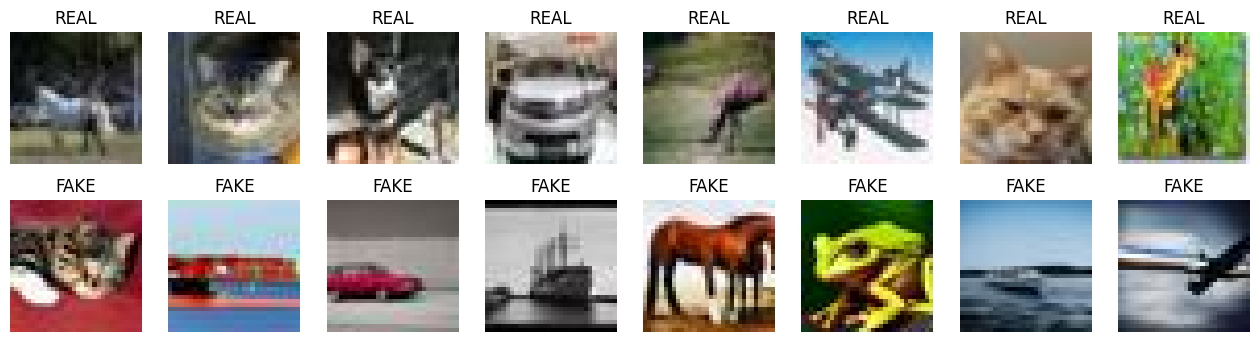

In [4]:
real_idx = np.where(y_train == 0)[0][:8]   # positions of the first 8 REAL images
fake_idx = np.where(y_train == 1)[0][:8]   # positions of the first 8 FAKE images

fig, axes = plt.subplots(2, 8, figsize=(16, 4))

for i in range(8):
    axes[0, i].imshow(X_train[real_idx[i]].astype('uint8'))
    axes[0, i].set_title("REAL")
    axes[0, i].axis('off')

    axes[1, i].imshow(X_train[fake_idx[i]].astype('uint8'))
    axes[1, i].set_title("FAKE")
    axes[1, i].axis('off')

plt.show()